# Ex1 — Runtime scaling figure
Plot the recorded per-window timing measurements used in the paper.

In [ ]:
from utils import configure_runtime
configure_runtime()
import numpy as np
import matplotlib.pyplot as plt

from utils import ROOT

RUN_DIR = ROOT / "runs" / "Ex1"
with np.load(RUN_DIR / "point_results.npz") as data:
    parameter_counts = np.unique(data["nn_params"])
    matrix_free_median_ms = np.array([np.median(data["ours_ms"][data["nn_params"] == n]) for n in parameter_counts])
    explicit_median_ms = np.array([np.median(data["leo_ms"][data["nn_params"] == n]) for n in parameter_counts])
largest_speedup = explicit_median_ms[-1] / matrix_free_median_ms[-1]


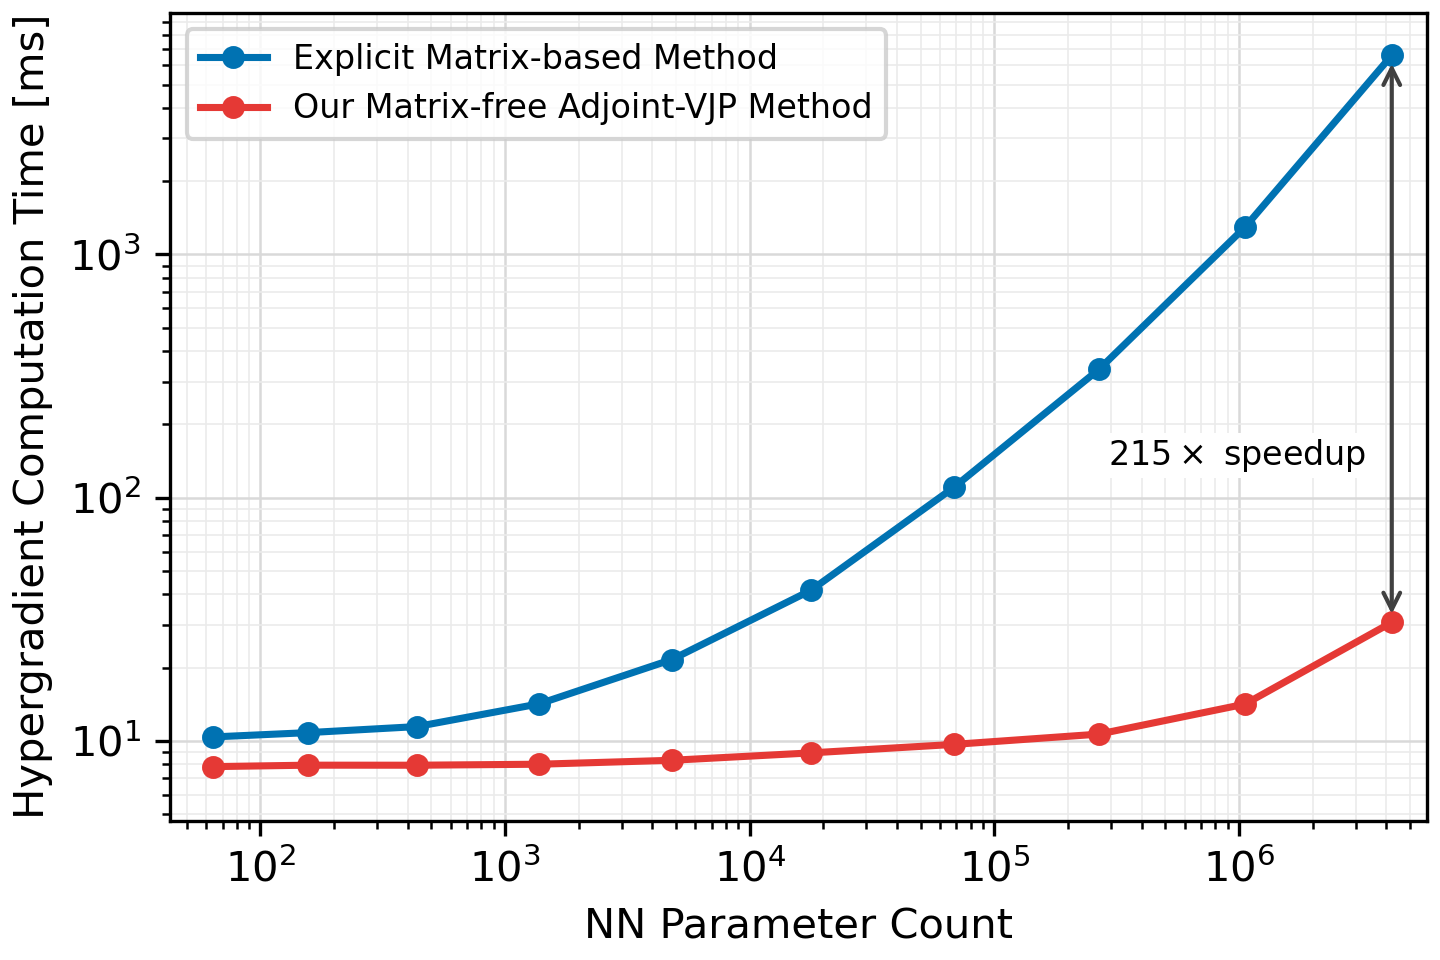

In [ ]:
fig, ax = plt.subplots(figsize=(4.8, 3.2), constrained_layout=True)
ax.loglog(
    parameter_counts, matrix_free_median_ms, "o-", color="#E53935", linewidth=1.7,
    markersize=4.5, label="Our Matrix-free Adjoint-VJP Method",
)
ax.loglog(
    parameter_counts, explicit_median_ms, "o-", color="#0072B2", linewidth=1.7,
    markersize=4.5, label="Explicit Matrix-based Method",
)
ax.set_xlabel("NN Parameter Count")
ax.set_ylabel("Hypergradient Computation Time [ms]")
ax.grid(True, which="major", color="0.85", linewidth=0.6)
ax.grid(True, which="minor", color="0.92", linewidth=0.4)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], frameon=True, fontsize=8, loc="upper left")

# Show the vertical runtime ratio at the largest saved network size.
annotation_x = parameter_counts[-1]
ax.annotate(
    "", xy=(annotation_x, explicit_median_ms[-1]),
    xytext=(annotation_x, matrix_free_median_ms[-1]),
    arrowprops=dict(arrowstyle="<->", color="0.25", linewidth=1.0),
)
ax.annotate(
    rf"${largest_speedup:.0f}\times$ speedup",
    xy=(annotation_x, np.sqrt(explicit_median_ms[-1] * matrix_free_median_ms[-1])),
    xytext=(-6, -28), textcoords="offset points", ha="right", va="center", fontsize=8,
    bbox=dict(facecolor="white", edgecolor="none", pad=1.0),
)
ax.set_xlim(parameter_counts[0] / 1.5, parameter_counts[-1] * 1.4)
ax.set_ylim(min(matrix_free_median_ms) * 0.6, max(explicit_median_ms) * 1.5)


fig.savefig(RUN_DIR / "Ex1_runtime_scaling.pdf")
fig.savefig(RUN_DIR / "Ex1_runtime_scaling.png", dpi=300)
plt.show()
